# CA1 Data Preparation Ciaran Lynch

## Add python libraries to analysis

In [1]:
import pandas as pd
import seaborn as sns
%matplotlib inline  
import matplotlib.pyplot as plt
import numpy as np


### The assignment requires us to carried out analysis of a csv named student_dataV2
###  This csv was also attached with an excel file called student_data_Dictionary.
###  This excel file gave us a description of the variable names listed with a number value and  their associate meaning

In [2]:
# dict = pd.read_excel("student_data_dictionary.xlsx")

In [3]:
# dict

## Load the Dataset provided called student_dataV2

In [4]:
df = pd.read_csv("student_dataV2.csv")

## Exploratory Data Analysis

# Characterisation of the data set

### Check  the data loaded correctly

In [5]:
df.head(5)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17.0,5.0,171.0,1,1,122.0,1,19,12.0,...,0,0.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15.0,1.0,9254.0,1,1,160.0,1,1,3.0,...,0,6.0,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1.0,5.0,9070.0,1,1,122.0,1,37,37.0,...,0,6.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17.0,2.0,9773.0,1,1,122.0,1,38,37.0,...,0,6.0,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39.0,1.0,8014.0,0,1,100.0,1,37,38.0,...,0,6.0,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   object 
 1   Application mode                                4423 non-null   float64
 2   Application order                               4423 non-null   float64
 3   Course                                          4421 non-null   float64
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4420 non-null   float64
 7   Nacionality                                     4424 non-null   object 
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

### From the info above, there seems to be a lot of rows, that would be categorical in nature, but listed as either float ot int
###  These have been given a numeric code to equal a categorical value
###  ie for course - "Biofuel Production Technologies" is listed as 33
### Gender is also listed as numeric where 1=male and 0=female

In [7]:
df.shape

(4424, 37)

#### We can see that the dataset contains 4424 rows of data and  37 columns
#### and we have a target categorical variable with a classification task
#### (dropout, enrolled, and graduate) at the end of the normal duration of the course

### Rename the columns to make it more readable

In [8]:
df = df.rename(columns={
    "Marital status": "maritial_status",
    "Application mode": "application_mode",
    "Application order": "application_order",
    "Course": "course",
    "Daytime/evening attendance": "course_time",
    "Previous qualification": "previous_qual",
    "Previous qualification (grade)": "previous_grade",
    "Nacionality": "nationality",
    "Mother's qualification": "mothers_qual",
    "Father's qualification": "fathers_qual",
    "Mother's occupation": "mothers_occupation",
    "Father's occupation": "fathers_occupation",
    "Admission grade": "admission_grade",
    "Educational special needs": "special_needs",
    "Debtor": "debtor",
    "Tuition fees up to date": "tuition_paid",
    "Gender": "gender",
    "Scholarship holder" : "scholarship_holder",
    "Age at enrollment": "enrollment_age",
    "International": "international",
    "Curricular units 1st sem (credited)": "1st_sem_credit",
    "Curricular units 1st sem (enrolled)": "1st_sem_enrolled",
    "Curricular units 1st sem (evaluations)": "1st_sem_evaluation",
    "Curricular units 1st sem (approved)": "1st_sem_approved",
    "Curricular units 1st sem (grade)": "1st_sem_grade",
    "Curricular units 1st sem (without evaluations)": "1st_sem_without_eval",
    "Curricular units 2nd sem (credited) ": "2nd_sem_credit",
    "Curricular units 2nd sem (enrolled) ": "2nd_sem_enrolled",
    "Curricular units 2nd sem (evaluations)": "2nd_sem_evaluation",
    "Curricular units 2nd sem (approved) ": "2nd_sem_approved",
    "Curricular units 2nd sem (grade)": "2nd_sem_grade",
    "Curricular units 2nd sem (without evaluations)": "1st_sem_without_eval",
    "Unemployment rate": "unemployed_rate",
    "Inflation rate": "inflation_rate"
    } 
    )

### create a map for variables- course, course attendance and gender
### Information taken from the data dictionary

In [9]:
# add course information
course_info_map = {
     33:	"Biofuel Production Technologies",
     171:	"Animation and Multimedia Design",
     8014:	"Social Service (evening attendance)",
     9003:	"Agronomy",
     9070:	"Communication Design",
     9085:	"Veterinary Nursing",
     9119: 	 "Informatics Engineering",
     9130: 	"Equinculture",
     9147: 	"Management",
     9238:	 "Social Service",
     9254:	 "Tourism",
     9500: 	"Nursing", 
     9556: 	"Oral Hygiene",
     9670: 	"Advertising and Marketing Management",
     9773: 	"Journalism and Communication",
     9853:   "Basic Education",
     9991: 	"Management (evening attendance)"
}

# add Attendance time
course_attendance_mapp = {
    1: "Daytime",
    0: "Evening"
}

# add gender map here also
gender_map = {
    1: "Male",
    0: "Female"
}

# add international map here also
international_map = {
    1: "Yes",
    0: "No"
}

# add map for scholarship_holder
scholar_map = {
    1: "Yes",
    0: "No"
}

# Add Maritial Status mapp, note it's listed as an object, so put Quotations on the number values

maritial_map = {
        "1": "single",
        "2": "married",
        "3" : "widower",
        "4": "divorced",
        "5" : "facto union",
        "6" : "legally seperated"
    }

# Add Parents Qualification Map, currently listed as int and float.  shouild be categorical Values
# Per review od data Dictionary, both mothers Qualification & Fathers have the same data
# Note also p(revious_qualification) variable is the same values, although a no15 category was added
parents_qual_map = {
        1  : "Secondary Education - 12th Year of Schooling or Eq",
        2  : "Higher Education - Bachelor's Degree",
        3  : "Higher Education - Degree",
        4  : "Higher Education - Master's ",
        5  : "Higher Education - Doctorate",
        6  : "Frequency of Higher Education",
        9 : "12th Year of Schooling - Not Completed",
        10 : "11th Year of Schooling - Not Completed",
        11 : "7th Year (Old)",
        12  : "Other - 11th Year of Schooling",
        13 : " 2nd year complementary high school course",
        14  : "10th Year of Schooling",
        15 : "10th year of schooling - not completed",
        18 : "General commerce course",
        19  : "Basic Education 3rd Cycle (9th/10th/11th Year) or Equiv",
        20  : "Complementary High School Course",
        22  : "Technical-professional course",
        25 : "Complementary High School Course - not concluded",
        26  : "7th year of schooling",
        27 : "2nd cycle of the general high school course",
        29 : "9th Year of Schooling - Not Completed",
        30 : "8th year of schooling",
        31  : "General Course of Administration and Commerce",
        33 : "Supplementary Accounting and Administration",
        34 : "Unknown",
        35 : "Can't read or write",
        36 : "Can read without having a 4th year of schooling ",
        37 : "Basic education 1st cycle (4th/5th year) or equiv",
        38 : "Basic Education 2nd Cycle (6th/7th/8th Year) or Equiv",
        39 : "Technological specialization course",
        40 : "Higher education - degree (1st cycle)",
        41 : "Specialized higher studies course",
        42 : "Professional higher technical course",
        43 : "Higher Education - Master (2nd cycle)",
        44 : "Higher Education - Doctorate (3rd cycle)"
}

# Add a map for nationality, currently listed as an object, so put quotation marks on the numbers
nationality_map = {
        "1"  : "Portuguese",
        "2" : "German",
        "6" : "Spanish;",
        "11" : "Italian;",
        "13"  : "Dutch",
        "14" : "English",
        "17" : "Lithuanian",
        "21" : "Angolan",
        "22" : "Cape Verdean",
        "24" : "Guinean",
        "25" : "Mozambican",
        "26" : "Santomean",
        "32" : "Turkish;",
        "41" : "Brazilian",
        "62" : " Romanian",
        "100"  : "Moldova (Republic of)",
        "101"  : "Mexican;",
        "103"  : "Ukrainian",
        "105"  : "Russian",
        "108"  : "Cuban",
        "109"  : "Colombia"
}


    


### Assign the map values to corresponding columns
### Add a course_name variable

In [10]:
df["course_name"] = df["course"].map(course_info_map) # create a new column wih course name
df["course_time"] = df["course_time"].map(course_attendance_mapp)
df["gender"] = df["gender"].map(gender_map)
df["maritial_status"] = df["maritial_status"].map(maritial_map)
df["mothers_qual"] = df["mothers_qual"].map(parents_qual_map)
df["fathers_qual"] = df["fathers_qual"].map(parents_qual_map)
df["previous_qual"] = df["previous_qual"].map(parents_qual_map)
df["nationality"] = df["nationality"].map(nationality_map)
df["international"] = df["international"].map(international_map)
df["scholarship_holder"] = df["scholarship_holder"].map(scholar_map)

In [11]:
df.columns.tolist()

['maritial_status',
 'application_mode',
 'application_order',
 'course',
 'course_time',
 'previous_qual',
 'previous_grade',
 'nationality',
 'mothers_qual',
 'fathers_qual',
 'mothers_occupation',
 'fathers_occupation',
 'admission_grade',
 'Displaced',
 'special_needs',
 'debtor',
 'tuition_paid',
 'gender',
 'scholarship_holder',
 'enrollment_age',
 'international',
 '1st_sem_credit',
 '1st_sem_enrolled',
 '1st_sem_evaluation',
 '1st_sem_approved',
 '1st_sem_grade',
 '1st_sem_without_eval',
 'Curricular units 2nd sem (credited)',
 'Curricular units 2nd sem (enrolled)',
 '2nd_sem_evaluation',
 'Curricular units 2nd sem (approved)',
 '2nd_sem_grade',
 '1st_sem_without_eval',
 'unemployed_rate',
 'inflation_rate',
 'GDP',
 'Target',
 'course_name']

In [12]:
df.head(3)

,maritial_status,application_mode,application_order,course,course_time,previous_qual,previous_grade,nationality,mothers_qual,fathers_qual,...,Curricular units 2nd sem (enrolled),2nd_sem_evaluation,Curricular units 2nd sem (approved),2nd_sem_grade,1st_sem_without_eval,unemployed_rate,inflation_rate,GDP,Target,course_name
0,single,17.0,5.0,171.0,Daytime,Secondary Education - 12th Year of Schooling o...,122.0,Portuguese,Basic Education 3rd Cycle (9th/10th/11th Year)...,Other - 11th Year of Schooling,...,0.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout,Animation and Multimedia Design
1,single,15.0,1.0,9254.0,Daytime,Secondary Education - 12th Year of Schooling o...,160.0,Portuguese,Secondary Education - 12th Year of Schooling o...,Higher Education - Degree,...,6.0,6,6,13.666667,0,13.9,-0.3,0.79,Graduate,Tourism
2,single,1.0,5.0,9070.0,Daytime,Secondary Education - 12th Year of Schooling o...,122.0,Portuguese,Basic education 1st cycle (4th/5th year) or equiv,Basic education 1st cycle (4th/5th year) or equiv,...,6.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout,Communication Design


## Data Preparation

## Analysis on variable columns
### 1.  Carry out analysis of the Target Column

In [13]:
df["Target"].unique()

array(['Dropout', 'Graduate', 'Enrolled', 'Grad', 'graduate', 'Drop',
       'dropout'], dtype=object)

### From review of the unique rows, we can see errors in categorising the variables, 
###  with incorrect wording, ie Grad instead of Graduate
### These need to be replaced, by using the .replace method

In [14]:
df["Target"] = df["Target"].replace(
    {
        "Grad": "Graduate",
        "graduate": "Graduate",
        "Drop" : "Dropout",
        "dropout": "Dropout"
    }
)

In [15]:
df["Target"].unique()

array(['Dropout', 'Graduate', 'Enrolled'], dtype=object)

### Create a new interger field from the Target
###  for correlation puropse, based on Graduated = 1, else 0

In [16]:
df["Graduated"]= df["Target"].map(
    {"Dropout": 0,
     "Enrolled": 0,
     "Graduate":1}
)

In [17]:
df["Graduated"].unique()

array([0, 1])

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 39 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   maritial_status                      4423 non-null   object 
 1   application_mode                     4423 non-null   float64
 2   application_order                    4423 non-null   float64
 3   course                               4421 non-null   float64
 4   course_time                          4424 non-null   object 
 5   previous_qual                        4424 non-null   object 
 6   previous_grade                       4420 non-null   float64
 7   nationality                          4423 non-null   object 
 8   mothers_qual                         4424 non-null   object 
 9   fathers_qual                         4423 non-null   object 
 10  mothers_occupation                   4423 non-null   float64
 11  fathers_occupation            

### 2. Carry out analysis of course information

In [19]:
df["course"].unique()

array([ 171., 9254., 9070., 9773., 8014., 9991., 9500., 9238., 9670.,
       9853., 9085., 9130., 9556., 9147., 9003.,   33., 9119.,   nan])

### We have some nan missing values
###  for course information
### Check below the values

In [20]:
df[df["course"].isna()]

,maritial_status,application_mode,application_order,course,course_time,previous_qual,previous_grade,nationality,mothers_qual,fathers_qual,...,2nd_sem_evaluation,Curricular units 2nd sem (approved),2nd_sem_grade,1st_sem_without_eval,unemployed_rate,inflation_rate,GDP,Target,course_name,Graduated
649,single,1.0,1.0,NaN,Daytime,Secondary Education - 12th Year of Schooling o...,117.0,Portuguese,Secondary Education - 12th Year of Schooling o...,Basic Education 2nd Cycle (6th/7th/8th Year) o...,...,5,4,10.75,0,9.4,-0.8,-3.12,Graduate,NaN,1
3681,facto union,39.0,1.0,NaN,Daytime,Secondary Education - 12th Year of Schooling o...,133.1,Portuguese,Basic Education 3rd Cycle (9th/10th/11th Year)...,Basic Education 3rd Cycle (9th/10th/11th Year)...,...,5,5,10.20,0,11.1,0.6,2.02,Enrolled,NaN,0
3823,single,NaN,1.0,NaN,Daytime,Technological specialization course,130.0,Portuguese,Basic Education 2nd Cycle (6th/7th/8th Year) o...,Basic Education 3rd Cycle (9th/10th/11th Year)...,...,8,2,13.50,0,11.1,0.6,2.02,Dropout,NaN,0


### There are 3 missing values for course information

### Show results of course information

In [21]:
df[ ["course", "course_name", "course_time"] ].head(5)

,course,course_name,course_time
0,171.0,Animation and Multimedia Design,Daytime
1,9254.0,Tourism,Daytime
2,9070.0,Communication Design,Daytime
3,9773.0,Journalism and Communication,Daytime
4,8014.0,Social Service (evening attendance),Evening


In [22]:
df["course_name"].value_counts()

course_name
Nursing                                 766
Management                              379
Social Service                          355
Veterinary Nursing                      337
Journalism and Communication            331
Management (evening attendance)         268
Advertising and Marketing Management    267
Tourism                                 252
Communication Design                    226
Animation and Multimedia Design         215
Social Service (evening attendance)     215
Agronomy                                210
Basic Education                         192
Informatics Engineering                 170
Equinculture                            140
Oral Hygiene                             86
Biofuel Production Technologies          12
Name: count, dtype: int64

### 3. Carry Out Analysis of Course Attendance time

In [23]:
df["course_time"].unique()

array(['Daytime', 'Evening'], dtype=object)

In [24]:
df["course_time"].value_counts()

course_time
Daytime    3941
Evening     483
Name: count, dtype: int64

### Show the same value counts of Attendance as a percentage, rounded to 2 decimals

In [25]:
round(df["course_time"].value_counts(normalize=True) * 100,2)

course_time
Daytime    89.08
Evening    10.92
Name: proportion, dtype: float64

### From the above value counts, we see that the majority of the students are daytime attenders
### With 89.08% attending a Daytime course

### 4. Carry out analysis of gender variable
### Currently listed as an int with 1's and 0's
### 1 = male and 0 = female

In [26]:
df["gender"].unique()

array(['Male', 'Female'], dtype=object)

In [27]:
df["gender"].unique()

array(['Male', 'Female'], dtype=object)

In [28]:
round(df["gender"].value_counts(normalize=True) * 100,2)

gender
Female    64.83
Male      35.17
Name: proportion, dtype: float64

### No errors found in the gender / gender code analysis
### We have a slightly higher Female representation at 64.83% of the Student population

### 5. Carry out on maritial_status

In [29]:
df["maritial_status"].unique()

array(['single', 'married', 'divorced', nan, 'widower', 'facto union',
       'legally seperated'], dtype=object)

### Again we can see that more errors have been discovered


In [30]:
df[df["maritial_status"].isna()]

,maritial_status,application_mode,application_order,course,course_time,previous_qual,previous_grade,nationality,mothers_qual,fathers_qual,...,2nd_sem_evaluation,Curricular units 2nd sem (approved),2nd_sem_grade,1st_sem_without_eval,unemployed_rate,inflation_rate,GDP,Target,course_name,Graduated
154,NaN,43.0,1.0,9853.0,Daytime,Secondary Education - 12th Year of Schooling o...,115.0,Portuguese,Higher Education - Degree,Basic education 1st cycle (4th/5th year) or equiv,...,12,3,10.0,0,9.4,-0.8,-3.12,Dropout,Basic Education,0


### Only 1 field with Maritial Status incomplete

In [31]:
df["maritial_status"].value_counts()

maritial_status
single               3918
married               379
divorced               91
facto union            25
legally seperated       6
widower                 4
Name: count, dtype: int64

### Show Table as a Percentage

In [32]:
round(df["maritial_status"].value_counts(normalize=True) * 100,2)

maritial_status
single               88.58
married               8.57
divorced              2.06
facto union           0.57
legally seperated     0.14
widower               0.09
Name: proportion, dtype: float64

### From the above value counts
### We can see that the vast majority of our students are single = 88.58%

### 6. Carry out analysis of enrollment_age

In [33]:
df["enrollment_age"].unique()

array(['20', '19', '45', '50', '18', '22', '21', '34', '37', '43', '55',
       '39', '29', '24', '27', '23', '26', '33', '35', '25', '44', '36',
       '47', '28', '38', 'UnKnown', '30', '31', '32', '40', '42', '48',
       '49', '46', '41', '70', '60', '53', '51', '52', '54', '61', '58',
       '59', '17', '57', '62', nan], dtype=object)

####  More errors can be seen in the enrollment age
#### See the presence of unknown, nan variables in the rows
####  replace unknown to nan using numpy

In [34]:
df["enrollment_age"] = df["enrollment_age"].replace("UnKnown", np.nan)

In [35]:
df["enrollment_age"].unique()

array(['20', '19', '45', '50', '18', '22', '21', '34', '37', '43', '55',
       '39', '29', '24', '27', '23', '26', '33', '35', '25', '44', '36',
       '47', '28', '38', nan, '30', '31', '32', '40', '42', '48', '49',
       '46', '41', '70', '60', '53', '51', '52', '54', '61', '58', '59',
       '17', '57', '62'], dtype=object)

In [36]:
df["enrollment_age"].dtype

dtype('O')

### Here we can see that although it looks like a numeric field, it is actually an object
### Using pandas library, change type to int, use the errors=coerce to also change the nan rows as numeric

In [37]:
df["enrollment_age"] = pd.to_numeric(df["enrollment_age"], errors="coerce")

In [38]:
df["enrollment_age"].dtype

dtype('float64')

### There is quite a large spread of age values.
### For further analysis, it would be helpful to divide into age range bins, using the pandas cut method

In [39]:
df["age_range"] = pd.cut(
    df["enrollment_age"],
    bins = [0,19,23,30,40,50,100],
    labels=[
        "18-19",
        "20-23",
        "24-30",
        "31-40",
        "41-50",
        "Over50"
    ]
)

In [40]:
df["age_range"].value_counts()

age_range
18-19     1951
20-23     1202
24-30      607
31-40      437
41-50      182
Over50      43
Name: count, dtype: int64

### Show the age_range value counts as a percentage

In [41]:
round(df["age_range"].value_counts(normalize=True) * 100,2)

age_range
18-19     44.12
20-23     27.18
24-30     13.73
31-40      9.88
41-50      4.12
Over50     0.97
Name: proportion, dtype: float64

### With an age_range bin created, we can get a better understanding of the age of students
### We can now see that the 18-19 & 20-23 are the largest age ranges at the college
###  With 44.12% 18-19 age range and 27.18% of 20-23 age range
### In total 71.3% of students are under 24

### 7. Carry out analysis of tuition_paid

In [42]:
df["tuition_paid"].unique()

array(['1', '0', nan, '?'], dtype=object)

### More errors found - replace the ? with nan
### as per the excel dictionary
### Tuition paid = 1, else 0
### note this variable is an object so will need to be converted to numeric using pandas pd.to_numeric

In [43]:
df["tuition_paid"] = df["tuition_paid"].replace("?", np.nan)

In [44]:
# change to numeric before renaming the values
df["tuition_paid"] = pd.to_numeric(df["tuition_paid"], errors="coerce")

In [45]:
df["tuition_paid"].unique()

array([ 1.,  0., nan])

In [46]:
df[df["tuition_paid"].isna()]

,maritial_status,application_mode,application_order,course,course_time,previous_qual,previous_grade,nationality,mothers_qual,fathers_qual,...,Curricular units 2nd sem (approved),2nd_sem_grade,1st_sem_without_eval,unemployed_rate,inflation_rate,GDP,Target,course_name,Graduated,age_range
3838,single,1.0,1.0,9147.0,Daytime,Secondary Education - 12th Year of Schooling o...,115.0,Portuguese,Basic Education 2nd Cycle (6th/7th/8th Year) o...,Secondary Education - 12th Year of Schooling o...,...,1,10.0,0,7.6,2.6,0.32,Dropout,Management,0,20-23
4089,married,43.0,1.0,8014.0,Evening,10th Year of Schooling,133.1,Portuguese,Unknown,Unknown,...,1,13.0,1,9.4,-0.8,-3.12,Dropout,Social Service (evening attendance),0,31-40


### only 2 errors in the tuition paid variable
### Both of the students dropped out, 
### I imputed the missing values as 0, due to the small number of observations and they both dropped out of the course

In [47]:
df["tuition_paid"] = df["tuition_paid"].fillna(0)

In [48]:
df["tuition_paid"].unique()

array([1., 0.])

### 8. Carry out analysis of international variable
###  Mapped from 1= yes and 0= No

In [49]:
df["international"].value_counts()

international
No     4313
Yes     110
Name: count, dtype: int64

In [50]:
df["international"].unique()

array(['No', 'Yes', nan], dtype=object)

In [51]:
df[df["international"].isna()]

,maritial_status,application_mode,application_order,course,course_time,previous_qual,previous_grade,nationality,mothers_qual,fathers_qual,...,Curricular units 2nd sem (approved),2nd_sem_grade,1st_sem_without_eval,unemployed_rate,inflation_rate,GDP,Target,course_name,Graduated,age_range
352,single,1.0,4.0,171.0,Daytime,Secondary Education - 12th Year of Schooling o...,127.0,Portuguese,Secondary Education - 12th Year of Schooling o...,Secondary Education - 12th Year of Schooling o...,...,0,0.0,0,9.4,-0.8,-3.12,Dropout,Animation and Multimedia Design,0,18-19


In [52]:
df["international"] = df["international"].fillna("No")

### From the above missing data, we see that the nationality of the student is Portuguese
###  I imputed the data as No, die to nationality of student and the small number of observations

In [53]:
df["international"].value_counts()

international
No     4314
Yes     110
Name: count, dtype: int64

### 9. Carry out analysis by admission_grade, 
### currently correctly listed as a float

In [54]:
df["admission_grade"].unique()

array([127.3, 142.5, 124.8, 119.6, 141.5, 114.8, 128.4, 113.1, 129.3,
       123. , 130.6, 119.3, 130.2, 111.8, 137.1, 120.7, 137.4, 136.3,
       124.6, 120.3, 121.8, 125.5, 114.9, 123.9, 157. , 116.4, 131. ,
       122.1, 118.8, 150. , 130. , 138.8, 134.5, 131.4, 102.5, 128.8,
       122.9, 113.9, 120. , 121.1, 120.4, 100.6, 121.4, 109.7, 134.1,
       127.6, 132.4, 133.4, 126.1, 113.5, 121.3, 159.3, 129.1, 155.3,
       139.8, 115.2, 131.9, 126. , 120.9, 128.2, 120.1, 100. , 134. ,
       130.8, 135.8, 111.7, 132.9, 115.5, 106. , 117. , 110.2, 155.7,
       180.4, 110. , 161. , 117.6, 128.7, 112.2, 100.8, 105. , 114. ,
       137. , 124.9, 134.3, 111.5, 160. , 117.4, 122.2, 118.2, 106.7,
       108.2, 107. , 136.1, 115.3, 140.4, 113.4, 118.6, 122.3, 127.9,
       117.1, 145.3, 122.6, 128. , 123.7, 131.7, 133.2, 109.3, 113. ,
       157.9, 112.1, 174.7, 110.1,  99.7, 121. , 119.1, 124.7, 117.2,
       131.5, 121.7, 123.4, 132.8, 108.7, 138.1, 126.5, 127.4, 123.6,
       122. , 125.8,

In [55]:
df["admission_grade"].mean()

np.float64(126.98851198552693)

In [56]:
df["admission_grade"].min()

95.0

In [57]:
df["admission_grade"].max()

190.0

### No errors found in the rows for the admission_grade variable
###  This allowed me to carry out a few math functions
###  admission grades run from 95-190, with an average of 126.98

### 10. Carry out analysis of 1st and 2nd semester evaluations

In [58]:
df["1st_sem_evaluation"].unique()

array([ 0,  6,  8,  9, 10,  5,  7, 14, 12, 15, 13, 11,  1, 17, 18, 19, 21,
        4, 16,  3, 24,  2, 22, 45, 20, 26, 29, 36, 32, 23, 27, 31, 28, 25,
       33])

In [59]:
df["1st_sem_evaluation"].min()

0

In [60]:
df["1st_sem_evaluation"].max()

45

In [61]:
df["2nd_sem_evaluation"].unique()

array([ 0,  6, 10, 17,  8,  5,  7, 14,  9, 12, 11, 13, 19,  3, 15, 16,  4,
       18,  2, 21,  1, 26, 27, 22, 20, 24, 28, 23, 25, 33])

In [62]:
df["2nd_sem_evaluation"].min()

0

In [63]:
df["2nd_sem_evaluation"].max()

33

### No errors found with the evaluations fields
###  listed as integer fields, so i could carry out a few math functions

### 11. Carry out analysis of the 1st semester grade & 2nd semester grade

In [64]:
# df["1st_sem_grade"].unique()

In [65]:
df[df["1st_sem_grade"].isna()]

,maritial_status,application_mode,application_order,course,course_time,previous_qual,previous_grade,nationality,mothers_qual,fathers_qual,...,Curricular units 2nd sem (approved),2nd_sem_grade,1st_sem_without_eval,unemployed_rate,inflation_rate,GDP,Target,course_name,Graduated,age_range
4417,single,1.0,1.0,9070.0,Daytime,Secondary Education - 12th Year of Schooling o...,132.0,Portuguese,Secondary Education - 12th Year of Schooling o...,Secondary Education - 12th Year of Schooling o...,...,6,13.5,0,16.2,0.3,-0.92,Graduate,Communication Design,1,20-23


In [66]:
df["1st_sem_grade"].max()

18.875

In [67]:
# df["2nd_sem_grade"].unique()

In [68]:
df[df["2nd_sem_grade"].isna()]

,maritial_status,application_mode,application_order,course,course_time,previous_qual,previous_grade,nationality,mothers_qual,fathers_qual,...,Curricular units 2nd sem (approved),2nd_sem_grade,1st_sem_without_eval,unemployed_rate,inflation_rate,GDP,Target,course_name,Graduated,age_range
3696,single,43.0,1.0,9254.0,Daytime,Secondary Education - 12th Year of Schooling o...,112.0,Portuguese,Basic education 1st cycle (4th/5th year) or equiv,Basic education 1st cycle (4th/5th year) or equiv,...,5,NaN,0,9.4,-0.8,-3.12,Graduate,Tourism,1,20-23


In [69]:
df["2nd_sem_grade"].max()

18.571428571428573

### From analysis, both variables have 1 nan field
### They are listed as floats which allowed me to carry out a math function

## 11. Carry out Analysis parents Qualifications and previous Qualification
###  Previous the values were updated to the Data Dictionary values using the map function

In [70]:
df["mothers_qual"].unique()

array(['Basic Education 3rd Cycle (9th/10th/11th Year) or Equiv',
       'Secondary Education - 12th Year of Schooling or Eq',
       'Basic education 1st cycle (4th/5th year) or equiv',
       'Basic Education 2nd Cycle (6th/7th/8th Year) or Equiv',
       'Higher Education - Degree', "Higher Education - Master's ",
       'Professional higher technical course',
       "Higher Education - Bachelor's Degree", 'Unknown',
       'Other - 11th Year of Schooling',
       'Higher education - degree (1st cycle)',
       '12th Year of Schooling - Not Completed',
       'Higher Education - Doctorate',
       'Technological specialization course', '7th Year (Old)',
       'Specialized higher studies course', '8th year of schooling',
       '10th Year of Schooling', "Can't read or write",
       'Can read without having a 4th year of schooling ',
       'Frequency of Higher Education',
       '11th Year of Schooling - Not Completed',
       '9th Year of Schooling - Not Completed',
       'Higher

In [71]:
df["mothers_qual"].value_counts()

mothers_qual
Secondary Education - 12th Year of Schooling or Eq         1069
Basic education 1st cycle (4th/5th year) or equiv          1009
Basic Education 3rd Cycle (9th/10th/11th Year) or Equiv     953
Basic Education 2nd Cycle (6th/7th/8th Year) or Equiv       562
Higher Education - Degree                                   438
Unknown                                                     130
Higher Education - Bachelor's Degree                         83
Higher Education - Master's                                  49
Other - 11th Year of Schooling                               42
Higher Education - Doctorate                                 21
Higher education - degree (1st cycle)                         9
12th Year of Schooling - Not Completed                        8
Technological specialization course                           8
Specialized higher studies course                             6
Frequency of Higher Education                                 4
Professional higher technic

In [72]:
df["fathers_qual"].unique()

array(['Other - 11th Year of Schooling', 'Higher Education - Degree',
       'Basic education 1st cycle (4th/5th year) or equiv',
       'Basic Education 2nd Cycle (6th/7th/8th Year) or Equiv',
       'Secondary Education - 12th Year of Schooling or Eq',
       'Basic Education 3rd Cycle (9th/10th/11th Year) or Equiv',
       'Higher Education - Doctorate', "Higher Education - Master's ",
       'Unknown', "Higher Education - Bachelor's Degree",
       'Technological specialization course', '7th Year (Old)',
       '12th Year of Schooling - Not Completed', nan,
       'Can read without having a 4th year of schooling ',
       '7th year of schooling', 'Higher education - degree (1st cycle)',
       '10th Year of Schooling', 'Complementary High School Course',
       "Can't read or write", 'Specialized higher studies course',
       'Technical-professional course',
       ' 2nd year complementary high school course',
       '9th Year of Schooling - Not Completed',
       'Higher Educatio

In [73]:
df["fathers_qual"].value_counts()

fathers_qual
Basic education 1st cycle (4th/5th year) or equiv          1208
Basic Education 3rd Cycle (9th/10th/11th Year) or Equiv     968
Secondary Education - 12th Year of Schooling or Eq          904
Basic Education 2nd Cycle (6th/7th/8th Year) or Equiv       702
Higher Education - Degree                                   282
Unknown                                                     112
Higher Education - Bachelor's Degree                         68
Higher Education - Master's                                  39
Other - 11th Year of Schooling                               38
Technological specialization course                          20
Higher Education - Doctorate                                 18
7th Year (Old)                                               10
Can read without having a 4th year of schooling               8
12th Year of Schooling - Not Completed                        5
Higher education - degree (1st cycle)                         5
Technical-professional cour

In [74]:
df["previous_qual"].unique()

array(['Secondary Education - 12th Year of Schooling or Eq',
       'Basic Education 3rd Cycle (9th/10th/11th Year) or Equiv',
       'Professional higher technical course',
       'Technological specialization course',
       '11th Year of Schooling - Not Completed',
       'Higher Education - Degree',
       'Higher education - degree (1st cycle)',
       "Higher Education - Bachelor's Degree",
       "Higher Education - Master's ", 'Other - 11th Year of Schooling',
       'Higher Education - Master (2nd cycle)',
       '10th year of schooling - not completed',
       'Frequency of Higher Education',
       '12th Year of Schooling - Not Completed',
       'Basic Education 2nd Cycle (6th/7th/8th Year) or Equiv',
       'Higher Education - Doctorate', '10th Year of Schooling'],
      dtype=object)

In [75]:
df["previous_qual"].value_counts()

previous_qual
Secondary Education - 12th Year of Schooling or Eq         3717
Technological specialization course                         219
Basic Education 3rd Cycle (9th/10th/11th Year) or Equiv     162
Higher Education - Degree                                   126
Other - 11th Year of Schooling                               45
Higher education - degree (1st cycle)                        40
Professional higher technical course                         36
Higher Education - Bachelor's Degree                         23
Frequency of Higher Education                                16
12th Year of Schooling - Not Completed                       11
Higher Education - Master's                                   8
Basic Education 2nd Cycle (6th/7th/8th Year) or Equiv         7
Higher Education - Master (2nd cycle)                         6
11th Year of Schooling - Not Completed                        4
10th year of schooling - not completed                        2
Higher Education - Doctora

### No errors to report, as values have been updated as objects (strings) from the data dictionary excel sheet
### We do have unknown, but as its now an object, its not an issue

In [76]:
df.columns.tolist()

['maritial_status',
 'application_mode',
 'application_order',
 'course',
 'course_time',
 'previous_qual',
 'previous_grade',
 'nationality',
 'mothers_qual',
 'fathers_qual',
 'mothers_occupation',
 'fathers_occupation',
 'admission_grade',
 'Displaced',
 'special_needs',
 'debtor',
 'tuition_paid',
 'gender',
 'scholarship_holder',
 'enrollment_age',
 'international',
 '1st_sem_credit',
 '1st_sem_enrolled',
 '1st_sem_evaluation',
 '1st_sem_approved',
 '1st_sem_grade',
 '1st_sem_without_eval',
 'Curricular units 2nd sem (credited)',
 'Curricular units 2nd sem (enrolled)',
 '2nd_sem_evaluation',
 'Curricular units 2nd sem (approved)',
 '2nd_sem_grade',
 '1st_sem_without_eval',
 'unemployed_rate',
 'inflation_rate',
 'GDP',
 'Target',
 'course_name',
 'Graduated',
 'age_range']

## 12 Carry out analysis of Scholarship Holder

In [105]:
df["scholarship_holder"].unique()

array(['No', 'Yes'], dtype=object)

In [106]:
df[df["scholarship_holder"].isna()]

,maritial_status,application_mode,application_order,course,course_time,previous_qual,previous_grade,nationality,mothers_qual,fathers_qual,...,Curricular units 2nd sem (approved),2nd_sem_grade,1st_sem_without_eval,unemployed_rate,inflation_rate,GDP,Target,course_name,Graduated,age_range


In [107]:
df["scholarship_holder"].value_counts()

scholarship_holder
No     3311
Yes    1093
Name: count, dtype: int64

## Dealing with nan values

In [79]:
total_rows = len(df)
print("Total rows of data before dealing with missing rows: ", total_rows)

Total rows of data before dealing with missing rows:  4424


In [80]:
df = df.dropna()

In [81]:
new_rows = len(df)

In [82]:
print("rows of data after dropping missing values: " , new_rows)

rows of data after dropping missing values:  4404


In [83]:
total_dropped = total_rows -  new_rows
total_dropped

20

In [84]:
total_dropped / total_rows *100

0.45207956600361665

In [85]:
df.isnull().sum()

maritial_status                        0
application_mode                       0
application_order                      0
course                                 0
course_time                            0
previous_qual                          0
previous_grade                         0
nationality                            0
mothers_qual                           0
fathers_qual                           0
mothers_occupation                     0
fathers_occupation                     0
admission_grade                        0
Displaced                              0
special_needs                          0
debtor                                 0
tuition_paid                           0
gender                                 0
scholarship_holder                     0
enrollment_age                         0
international                          0
1st_sem_credit                         0
1st_sem_enrolled                       0
1st_sem_evaluation                     0
1st_sem_approved

## Missing rows analysis
#### in total only 20 rows had missing data, this represented 0.45% of the overall dataset
### dropping the missing data, will have a negligible impact on the overall sample size

## Discriptive Statistics

In [86]:
df.describe()

,application_mode,application_order,course,previous_grade,mothers_occupation,admission_grade,special_needs,debtor,tuition_paid,enrollment_age,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),2nd_sem_evaluation,Curricular units 2nd sem (approved),2nd_sem_grade,1st_sem_without_eval,unemployed_rate,inflation_rate,GDP,Graduated
count,4404.000000,4404.000000,4404.000000,4404.000000,4404.000000,4404.000000,4404.000000,4404.000000,4404.000000,4404.000000,...,4404.000000,4404.000000,4404.000000,4404.000000,4404.000000,4404.000000,4404.000000,4404.000000,4404.000000,4404.000000
mean,18.665758,1.729110,8856.561535,132.626885,10.985695,126.986717,0.011580,0.113987,0.879882,23.271571,...,0.542916,6.233651,8.064033,4.435059,10.225887,0.150772,11.567598,1.229950,0.004015,0.498865
std,17.464334,1.314832,2063.769546,13.198789,26.474865,14.480995,0.106999,0.317832,0.325136,7.597548,...,1.921399,2.197524,3.950694,3.017190,5.215408,0.755311,2.665350,1.382119,2.267198,0.500055
min,1.000000,0.000000,33.000000,95.000000,0.000000,95.000000,0.000000,0.000000,0.000000,17.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000,0.000000
25%,1.000000,1.000000,9085.000000,125.000000,4.000000,117.900000,0.000000,0.000000,1.000000,19.000000,...,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000,0.000000
50%,17.000000,1.000000,9238.000000,133.100000,5.000000,126.100000,0.000000,0.000000,1.000000,20.000000,...,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000,0.000000
75%,39.000000,2.000000,9556.000000,140.000000,9.000000,134.800000,0.000000,0.000000,1.000000,25.000000,...,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000,1.000000
max,53.000000,9.000000,9991.000000,190.000000,194.000000,190.000000,1.000000,1.000000,1.000000,70.000000,...,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000,1.000000


#### Check the target column for value counts

In [87]:
df["Target"].value_counts()

Target
Graduate    2197
Dropout     1419
Enrolled     788
Name: count, dtype: int64

### Show Student outcomes on a chart

Text(0.5, 1.0, 'Student Outcomes')

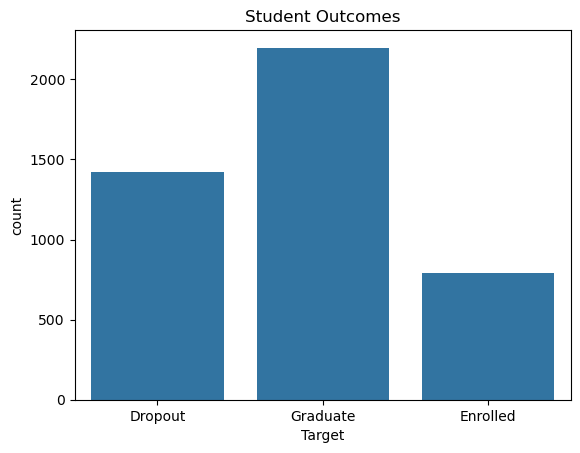

In [88]:
sns.countplot(
    data=df,
    x="Target")

plt.title("Student Outcomes")

### The above Target outcome shows a balanced result, with 2,198 Graduates and 1,416 Dropouts, we also had 788 enrolled
### Graduates were the largest category, showing that course completions were the most common
### Although a large dropout rate may require further analysis

Text(0.5, 1.0, 'Student maritial status')

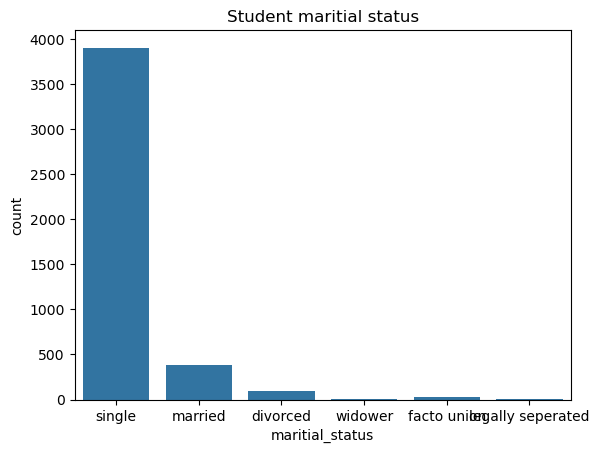

In [89]:
sns.countplot(
    data=df,
    x="maritial_status")

plt.title("Student maritial status")

Text(0.5, 1.0, 'Students by age range')

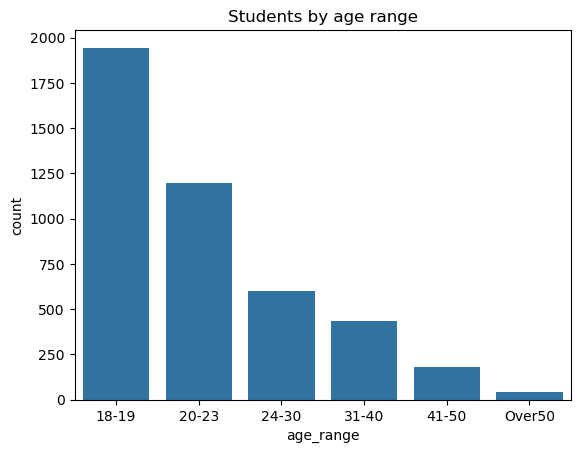

In [90]:
sns.countplot(
    data=df,
    x="age_range")

plt.title("Students by age range")

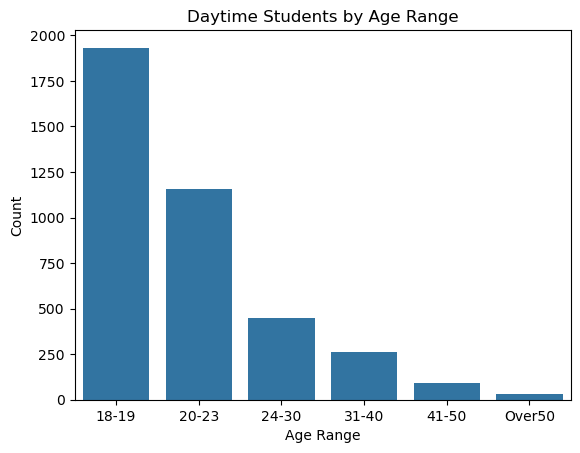

In [91]:
sns.countplot(
    data=df[df["course_time"] ==  "Daytime"],
    x="age_range"
)

plt.title("Daytime Students by Age Range")
plt.xlabel("Age Range")
plt.ylabel("Count")
plt.show()

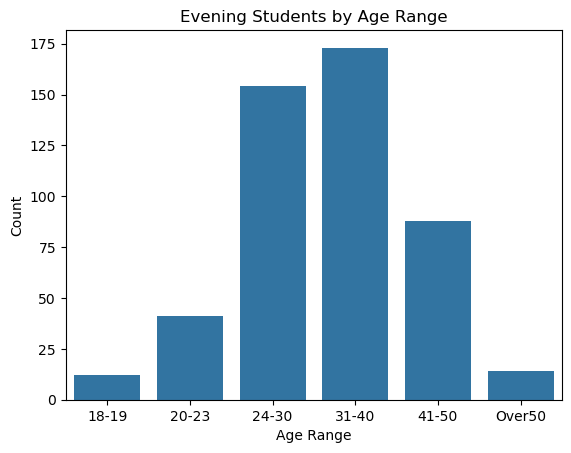

In [92]:
sns.countplot(
    data=df[df["course_time"] ==  "Evening"],
    x="age_range"
)

plt.title("Evening Students by Age Range")
plt.xlabel("Age Range")
plt.ylabel("Count")
plt.show()

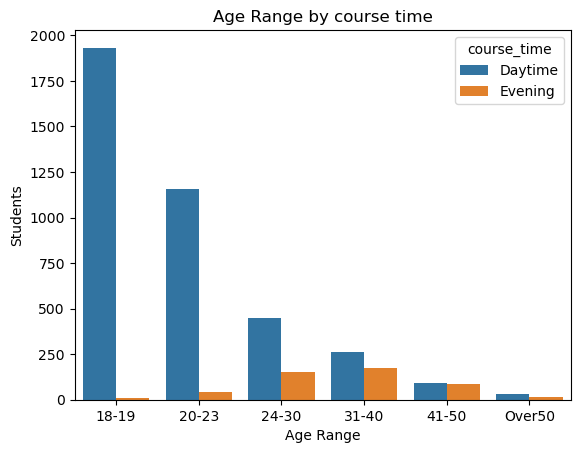

In [93]:
sns.countplot(
    data=df,
    x="age_range",
    hue="course_time"
)

plt.title("Age Range by course time")
plt.xlabel("Age Range")
plt.ylabel("Students")
plt.show()

## Chart analysis
###  We can see from the above charts that younger students dominate the daytime courses, particularly in the 18-19 and 20-23 age ranges
### Attendance of evening courses have more of an uptake with the older students
### This is to be expected given evening classes would generally be more part time for working adults

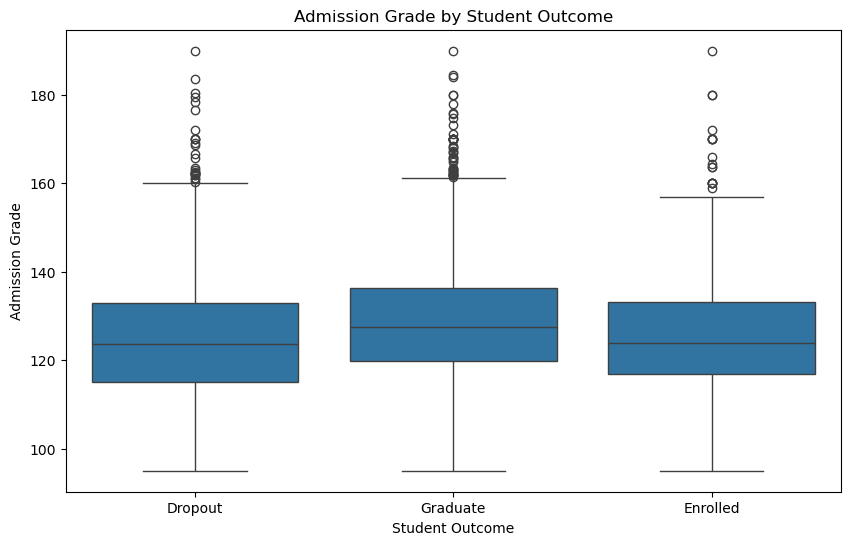

In [94]:
plt.figure(figsize=(10,6) )

sns.boxplot(
    data = df,
    x= df["Target"],
    y= df["admission_grade"]
)
   

plt.title("Admission Grade by Student Outcome" )
plt.xlabel("Student Outcome")
plt.ylabel("Admission Grade")

plt.show()

### Admission Grade Boxplot Analysis
### The above boxplot would suggest that students with higher admission grades tended to have higher graduation rates
### However the overlap detween groups indicates that admission grades alone does not fully explain outcomes

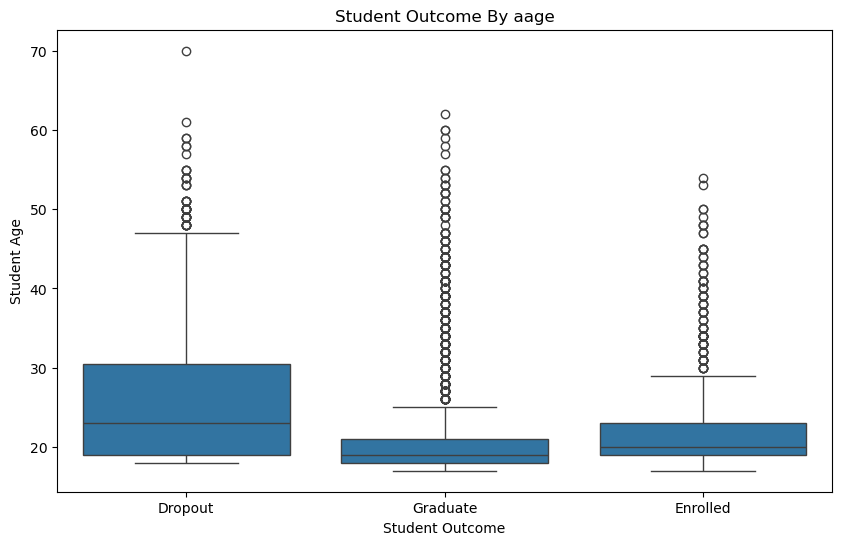

In [95]:
plt.figure(figsize=(10,6) )

sns.boxplot(
    data = df,
    x= df["Target"],
    y= df["enrollment_age"]
)
   

plt.title("Student Outcome By aage" )
plt.xlabel("Student Outcome")
plt.ylabel("Student Age")

plt.show()

## Enrollment Age Boxplot Analysis
### The above boxplot suggests Graduates tend to be slightly younger than those who dropped out
### Older students have a large variation in outcomes, this may be due to other committments outside of education

<Axes: xlabel='enrollment_age', ylabel='admission_grade'>

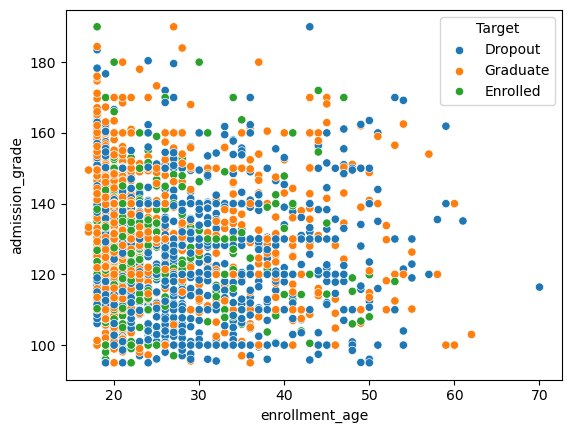

In [96]:
sns.scatterplot(
    data = df,
    x= "enrollment_age",
    y = "admission_grade",
    hue = "Target"
)

## Scatterplot Analysis
### There does not appear to be a strong linear relationship to enrollment age and admission grade
### However there is a larger concentration of graduates appearing with higher admission grades
### Suggesting higher admission grades leads to a higher chance of graduating

## Correlation

In [97]:
df_new = df[
    ["course",
     "enrollment_age", 
     "1st_sem_evaluation", 
     "2nd_sem_evaluation", 
     "1st_sem_grade",
     "2nd_sem_grade",
     "application_mode",
     "Graduated",
     "gender",
     "international",
     "tuition_paid",
     "course_time"
     
    ] 
    ].copy()

In [98]:
corr_matrix = df_new.corr(numeric_only=True)
corr_matrix

,course,enrollment_age,1st_sem_evaluation,2nd_sem_evaluation,1st_sem_grade,2nd_sem_grade,application_mode,Graduated,tuition_paid
course,1.000000,0.042698,0.271703,0.277771,0.388333,0.347771,0.064662,0.030207,0.018299
enrollment_age,0.042698,1.000000,0.139588,0.055875,-0.156523,-0.173255,0.516008,-0.194744,-0.177662
1st_sem_evaluation,0.271703,0.139588,1.000000,0.779026,0.417808,0.354784,0.225966,-0.004719,0.027663
2nd_sem_evaluation,0.277771,0.055875,0.779026,1.000000,0.487323,0.453335,0.166751,0.020960,0.063276
1st_sem_grade,0.388333,-0.156523,0.417808,0.487323,1.000000,0.836817,-0.118408,0.414208,0.250477
2nd_sem_grade,0.347771,-0.173255,0.354784,0.453335,0.836817,1.000000,-0.115911,0.474300,0.296464
application_mode,0.064662,0.516008,0.225966,0.166751,-0.118408,-0.115911,1.000000,-0.208121,-0.136024
Graduated,0.030207,-0.194744,-0.004719,0.020960,0.414208,0.474300,-0.208121,1.000000,0.328133
tuition_paid,0.018299,-0.177662,0.027663,0.063276,0.250477,0.296464,-0.136024,0.328133,1.000000


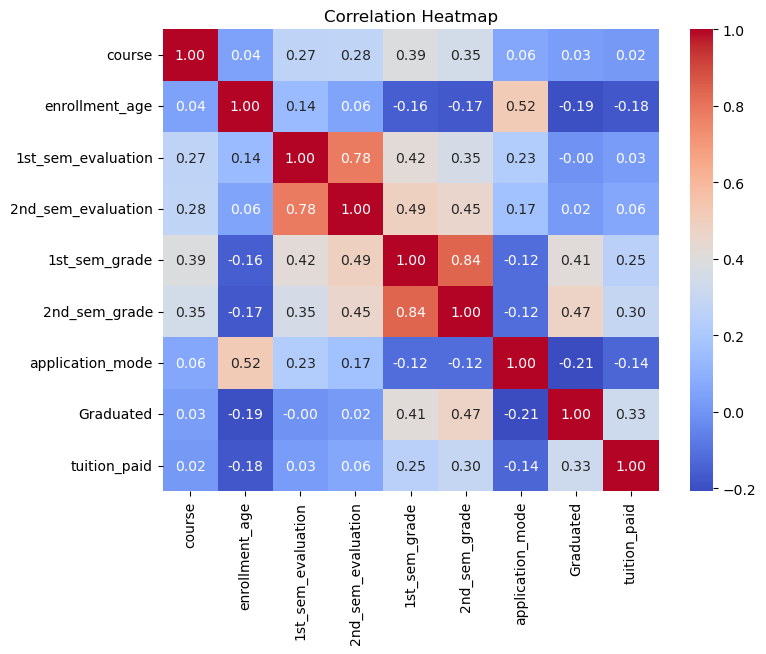

In [99]:
# create a seaborn heatmap
plt.figure(figsize=(8,6) )

sns.heatmap(
    corr_matrix,  
    annot=True,   
    cmap="coolwarm",  
    fmt=".2f" )      

plt.title("Correlation Heatmap")

plt.show()

### Correlation  analysis

### Measuring Graduated variable with all others:
### There is a noticeable positive correlation between Graduated to 1st semester grade and 2nd semester grade
### Indicating academic performance results in sucessful completion
### Also tuition paid has a 0.33 positive correlation to graduation 
### indicating that fullly paying for a course may be a positive driving factor in completion
### Notice also the strong positive correlation in 1st and 2nd semester grades along with evaluation

In [100]:
df.columns.tolist()

['maritial_status',
 'application_mode',
 'application_order',
 'course',
 'course_time',
 'previous_qual',
 'previous_grade',
 'nationality',
 'mothers_qual',
 'fathers_qual',
 'mothers_occupation',
 'fathers_occupation',
 'admission_grade',
 'Displaced',
 'special_needs',
 'debtor',
 'tuition_paid',
 'gender',
 'scholarship_holder',
 'enrollment_age',
 'international',
 '1st_sem_credit',
 '1st_sem_enrolled',
 '1st_sem_evaluation',
 '1st_sem_approved',
 '1st_sem_grade',
 '1st_sem_without_eval',
 'Curricular units 2nd sem (credited)',
 'Curricular units 2nd sem (enrolled)',
 '2nd_sem_evaluation',
 'Curricular units 2nd sem (approved)',
 '2nd_sem_grade',
 '1st_sem_without_eval',
 'unemployed_rate',
 'inflation_rate',
 'GDP',
 'Target',
 'course_name',
 'Graduated',
 'age_range']

### Create a Pivot Table to show Target by course name

In [101]:
# create a pivot table
pivot = pd.pivot_table (
    df,
    values="Graduated",
    index=["course_name", "gender"], # Further group course name by gender
    columns="Target",
    aggfunc="count",
    fill_value=0,
    margins = True
)
pivot

Target                                       Dropout  Enrolled  Graduate   All
course_name                          gender                                   
Advertising and Marketing Management Female       41        26        78   145
                                     Male         54        22        46   122
Agronomy                             Female       17         9        34    60
                                     Male         69        27        52   148
Animation and Multimedia Design      Female       36        15        47    98
                                     Male         46        22        48   116
Basic Education                      Female       80        46        55   181
                                     Male          4         3         2     9
Biofuel Production Technologies      Female        1         1         1     3
                                     Male          7         2         0     9
Communication Design                 Female       22        23        84   129
                                     Male         29        19        48    96
Equinculture                         Female       38        14        27    79
                                     Male         39         7        15    61
Informatics Engineering              Female        6         1         0     7
                                     Male         86        63        13   162
Journalism and Communication         Female       60        21       135   216
                                     Male         41        13        61   115
Management                           Female       54        63       101   218
                                     Male         80        44        37   161
Management (evening attendance)      Female       54        38        39   131
                                     Male         82        16        38   136
Nursing                              Female       81        76       459   616
                                     Male         37        24        88   149
Oral Hygiene                         Female       21        14        31    66
                                     Male         12         3         4    19
Social Service                       Female       43        39       226   308
                                     Male         22         3        21    46
Social Service (evening attendance)  Female       54        16       103   173
                                     Male         17         5        20    42
Tourism                              Female       52        17        82   151
                                     Male         44        23        30    97
Veterinary Nursing                   Female       59        64       152   275
                                     Male         31         9        20    60
All                                             1419       788      2197  4404

## Pivot Table Analysis
#### We can see above that Nursing was the most popular of the course offerings
### With 616 Females and 149 Males registering for Nursing
#### Nursing had 459 Female Graduates 74.5% and 88 Male Graduates = 59.06%
####  Resulting in an overall 71.5% Graduation rate in nursing
####  Biofuel Production Technologies was the least popular course
####  With only 1 Graduated from 12 registrations

In [102]:
# create a pivot table by course attendence time (day / Evening)
pivot_attend = pd.pivot_table (
    df,
    values="Graduated", # used as a count
    index=["course_time", "gender"],
    columns="Target",
    aggfunc="count",
    fill_value=0,
    margins = True
)
pivot_attend

Target              Dropout  Enrolled  Graduate   All
course_time gender                                   
Daytime     Female      611       429      1512  2552
            Male        601       284       485  1370
Evening     Female      108        54       142   304
            Male         99        21        58   178
All                    1419       788      2197  4404

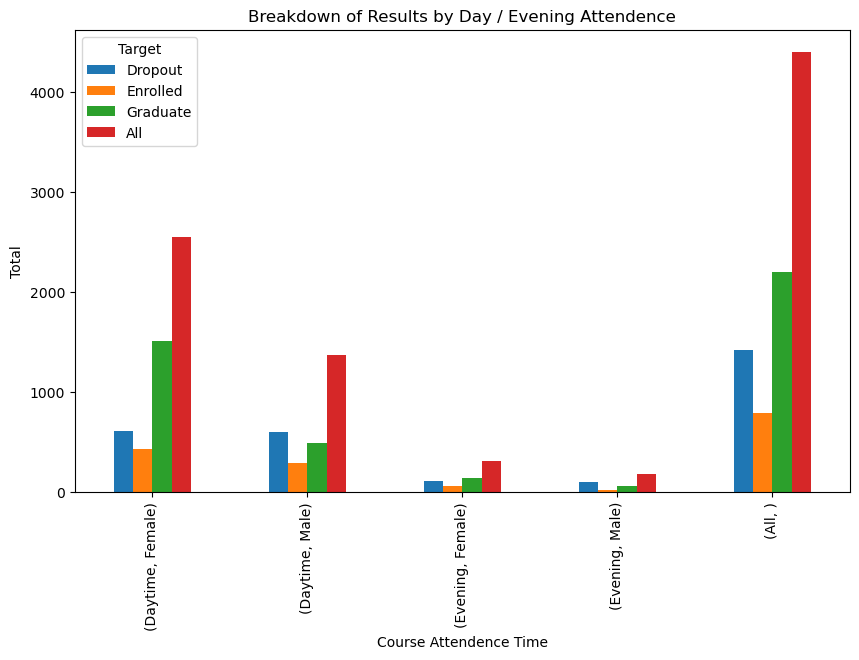

In [108]:
pivot_chart = pivot_attend.drop(
    index="Total",
    errors="ignore").drop(
    columns="Total",
    errors="ignore")

pivot_chart.plot(
    kind="bar",
    figsize=(10,6))

plt.title("Breakdown of Results by Day / Evening Attendence")
plt.xlabel("Course Attendence Time")
plt.ylabel("Total")


plt.show()

#### From the above chart and pivot table
#### We can see that although only 2 courses were offered in the evening
#### Graduates from those course we quite low with 201 Graduates from 483 registered = 41.61% Graduation rate
#### Daytime course have 2008 Graduates from 3941 registered = 50.95% Graduation rate

## Create a Frequency table by scholarship holders

In [121]:
pd.crosstab(
    [ df["scholarship_holder"], df["course_time"] ], # show as rows Yes, No
    df["Target"], # shows as columns, outcome
    normalize = "index" # show the values as percentage
).mul(100).round(2) # multiply by 100 and round to 2, to give a better overall % value

Target                          Dropout  Enrolled  Graduate
scholarship_holder course_time                             
No                 Daytime        37.50     20.60     41.89
                   Evening        47.85     15.31     36.84
Yes                Daytime        12.34     11.37     76.29
                   Evening        10.94     17.19     71.88

#### We can see from above Pandas Frequency Table
#### That scholarship holders (yes) have a 76.29% Graduate rate for Daytime courses
#### And 71.88% Graduation for Evening Courses
#### This suggests that scholarship holders attending Daytime courses
#### achieved the highest graduation rates

## PCA